# X-Ray Stitch: Classical vs Learned Feature Matching

Long-leg and full-spine radiographs are too tall for one detector, so they are taken as several overlapping exposures and stitched together. Each exposure differs slightly in position, angle and brightness, and an alignment error of a few pixels at the seam becomes an error in measured leg length or spinal angle.

Radiographs are hard to stitch: large smooth regions, few distinct corners, repeated structures (rulers, long bone shafts) and a different exposure for each shot. This notebook compares two ways of finding matching points between overlapping segments:

| | Method | Idea |
|---|---|---|
| **Classical** | CLAHE + SIFT + ratio test | Hand-designed gradient features |
| **Learned** | DISK + LightGlue | Features and matching learned from millions of image pairs |

Both feed the same RANSAC similarity estimate and the same feathered blending, so any difference comes from the matching.

**Measuring accuracy honestly:** a full image is cut into overlapping segments with misalignment we generate ourselves. The true transform is therefore known, and error is measured in pixels instead of judged by eye.

In [1]:
# Setup: works locally (run from notebooks/) and in Google Colab (use a GPU runtime for speed)
import os, sys
if "google.colab" in sys.modules and not os.path.exists("xraystitch"):
    !git clone https://github.com/Ebby-L/xraystitch.git
    %cd xraystitch
    !pip -q install kornia
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import glob, warnings
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore", category=UserWarning)

from xraystitch.matchers import DeepMatcher, SIFTMatcher
from xraystitch.phantom import long_leg_phantom
from xraystitch.stitch import chain_error, pair_errors, stitch
from xraystitch.synth import make_segments

METHOD_COLORS = {"SIFT": "#c27c12", "DISK + LightGlue": "#1d6b62"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
matchers = [SIFTMatcher(), DeepMatcher()]

## 1. Test images

Put your own radiographs (PNG or JPG) in `data/images/`. Without any, the notebook uses a procedural long-leg phantom, so it runs with no patient data.

In [2]:
paths = sorted(glob.glob("data/images/*.png") + glob.glob("data/images/*.jpg"))
images = {os.path.basename(p): cv2.imread(p, cv2.IMREAD_GRAYSCALE) for p in paths}
if not images:
    images = {"phantom": long_leg_phantom()}
print("Using:", ", ".join(f"{k} {v.shape}" for k, v in images.items()))
name, full = next(iter(images.items()))

Using: phantom (2400, 700)


## 2. Simulate three exposures

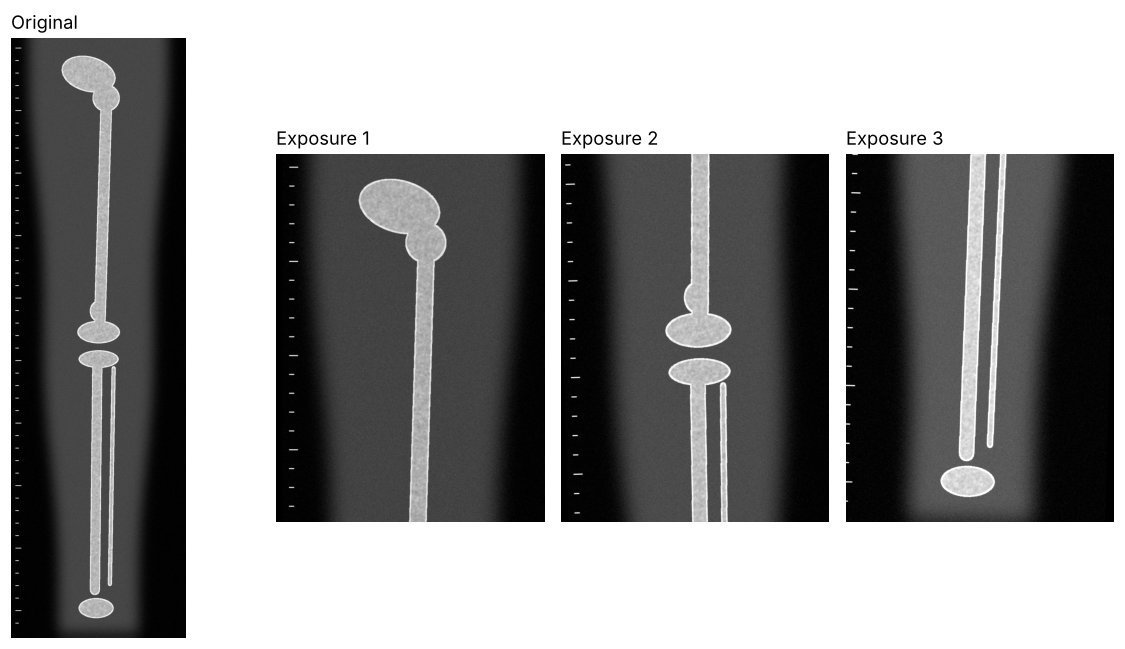

In [3]:
segs = make_segments(full, n=3, overlap=0.25, seed=1)
fig, axes = plt.subplots(1, 4, figsize=(11, 6), gridspec_kw={"width_ratios": [1.2, 1, 1, 1]})
axes[0].imshow(full, cmap="gray"); axes[0].set_title("Original", loc="left")
for i, (ax, s) in enumerate(zip(axes[1:], segs)):
    ax.imshow(s.image, cmap="gray"); ax.set_title(f"Exposure {i + 1}", loc="left")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Stitch with both methods

In [4]:
results = {m.name: stitch(segs, m) for m in matchers}
rows = []
for name_m, r in results.items():
    for i, (p, e) in enumerate(zip(r.pairs, pair_errors(segs, r))):
        rows.append({"method": name_m, "pair": f"{i + 1}→{i + 2}", "matches": p.matches,
                     "inliers": p.inliers, "error_px": round(e, 2), "seconds": round(p.seconds, 2)})
display(pd.DataFrame(rows))
print({k: round(chain_error(segs, r), 2) for k, r in results.items()}, "← end-of-chain error (px)")

,method,pair,matches,inliers,error_px,seconds
0,SIFT,1→2,72,50,0.97,0.27
1,SIFT,2→3,80,36,0.13,0.21
2,DISK + LightGlue,1→2,202,148,0.51,11.19
3,DISK + LightGlue,2→3,257,209,0.20,7.13


{'SIFT': 2.38, 'DISK + LightGlue': 1.2} ← end-of-chain error (px)


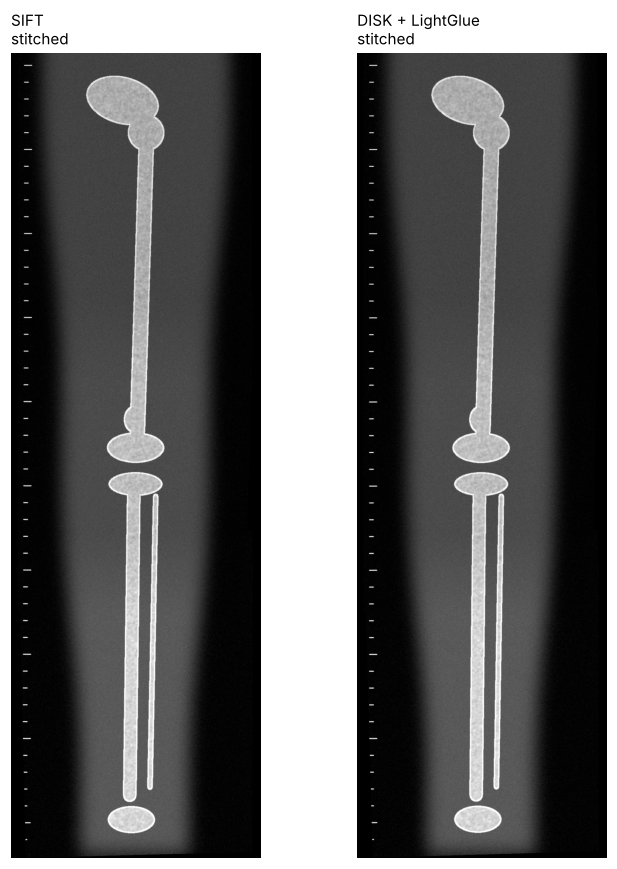

In [5]:
fig, axes = plt.subplots(1, len(results), figsize=(7, 8))
for ax, (name_m, r) in zip(np.atleast_1d(axes), results.items()):
    if r.mosaic is not None:
        ax.imshow(r.mosaic, cmap="gray")
    ax.set_title(f"{name_m}\n{'stitched' if r.ok else 'FAILED'}", loc="left", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Stress test: where does each method break?

Clinical acquisitions vary. Overlap between exposures can be small, and noise rises with lower dose. Each condition is repeated over several random poses; a pair counts as **successful** if its error is under 2 pixels.

In [6]:
conditions = [(ov, nz) for ov in (0.25, 0.15, 0.10) for nz in (4, 12)]
SEEDS = range(3)
records = []
for img_name, img in images.items():
    for ov, nz in conditions:
        for seed in SEEDS:
            s = make_segments(img, n=3, overlap=ov, noise=nz, seed=seed)
            for m in matchers:
                r = stitch(s, m, blend=False)
                for e in pair_errors(s, r):
                    records.append({"image": img_name, "overlap": ov, "noise": nz, "method": m.name,
                                    "error_px": e, "success": bool(e < 2.0)})
stress = pd.DataFrame(records)
summary = (stress.groupby(["overlap", "noise", "method"])
           .agg(success_rate=("success", "mean"), median_error_px=("error_px", "median"))
           .unstack("method").round(2))
summary

success_rate        median_error_px      
method        DISK + LightGlue  SIFT DISK + LightGlue  SIFT
overlap noise                                              
0.10    4                 0.83  0.50             0.99  1.98
        12                0.00  0.00             5.09   NaN
0.15    4                 1.00  0.83             0.66  1.31
        12                0.33  0.00             0.84   NaN
0.25    4                 1.00  1.00             0.33  0.60
        12                0.17  0.00             2.93  3.07

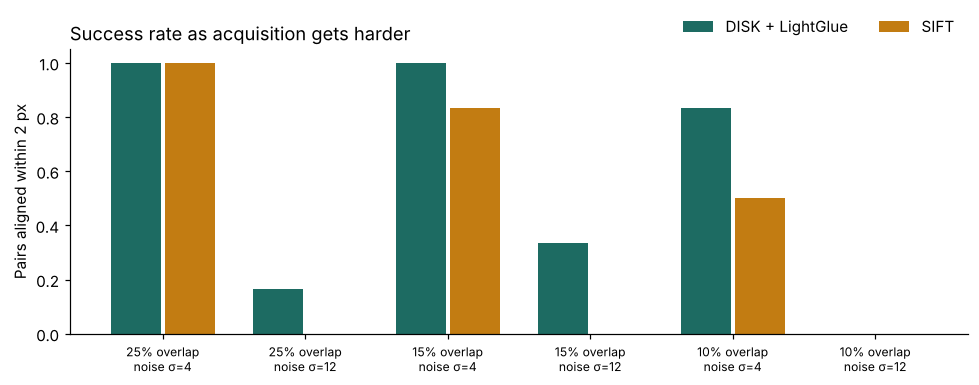

In [7]:
rate = (stress.groupby(["overlap", "noise", "method"])["success"].mean().unstack("method")
        .sort_index(level=["overlap", "noise"], ascending=[False, True]))  # easy → hard
labels = [f"{int(o * 100)}% overlap\nnoise σ={n}" for o, n in rate.index]
x = np.arange(len(rate)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 3.6))
for j, m in enumerate(rate.columns):
    ax.bar(x + (j - 0.5) * w, rate[m], w - 0.03, label=m, color=METHOD_COLORS[m])
ax.set_xticks(x, labels, fontsize=8); ax.set_ylim(0, 1.05)
ax.set_ylabel("Pairs aligned within 2 px")
ax.set_title("Success rate as acquisition gets harder", loc="left")
ax.legend(frameon=False, ncol=2, loc="lower right", bbox_to_anchor=(1, 1.0))
plt.tight_layout(); plt.show()

## 5. Findings

- **Normal acquisition (25% overlap, low noise):** both methods align every seam. DISK + LightGlue finds 3–5× more inliers and halves the end-of-chain error (1.20 px vs 2.38 px).
- **Small overlap:** SIFT breaks first. At 10% overlap it aligns half the seams; the learned matcher aligns 83%.
- **High noise:** both methods mostly fail. Neither should be trusted without a confidence check, which is why the pipeline reports failure instead of returning a bad stitch.
- **Cost:** on CPU the learned matcher is roughly 35× slower per seam. A GPU closes most of that gap.

## Limitations

- **Simulated misalignment.** Real exposures also differ by parallax and patient movement between shots, which a 2D similarity transform cannot model.
- **Pretrained, not fine-tuned.** DISK and LightGlue were trained on natural photographs, not radiographs. Fine-tuning on X-ray pairs is the obvious next step.
- **Phantom is simplified.** Real anatomy has more texture and more ambiguity; results should be confirmed on real radiographs.

## Next steps

- Fine-tune the learned matcher on radiograph pairs
- Detect and use the calibration ruler as an explicit alignment cue
- Report alignment confidence to the radiographer, so poor stitches are caught before measurement